In [25]:
#peak flux = 17.777

#peak flux error = 0.9005994239949303

#day of peak flux = 102.59999999999854

#orbital period (hours) 43 years --> 376938 hours

#vpeak = 8.314  

#t2 = 26.42199999978766  (day)

#velocity =  3200 ± 345


#Tick marks good 
# - Flux = 0 
#Non detections done correctly 


#Need to check spectral index values 

In [1]:
#Get the imports
import math
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline

from astropy.io import ascii
import astropy.units as u
import astropy.constants as const
from astropy.modeling.powerlaws import BrokenPowerLaw1D, SmoothlyBrokenPowerLaw1D, PowerLaw1D
from astropy.modeling import fitting, models

In [2]:
#The Radio data
#March 10, 2010 = t_0

V407_radio = pd.read_csv('V407Cyg_radio.dat', delim_whitespace = True, header = 0)

freq = V407_radio['Freq']
flux = V407_radio['Flux']
err = V407_radio['Err1']
mjd = V407_radio['MJD']



/var/folders/xv/dvsld6lx4xs_nbgh_qcl11d00000gn/T/ipykernel_85132/520170435.py:4: FutureWarning: The 'delim_whitespace' keyword in pd.read_csv is deprecated and will be removed in a future version. Use ``sep='\s+'`` instead
  V407_radio = pd.read_csv('V407Cyg_radio.dat', delim_whitespace = True, header = 0)


In [3]:
#mjd to date 
#mjd t_0 = 55265

def MJD_to_date(MJD, first):
    days = []
    for i in range(len(MJD)):
        days.append(float(MJD[i]) - first)
    return(days)

day = np.array(MJD_to_date(mjd,55265))

In [4]:
#Sort data by freq and non detections 

A = np.logical_and(freq>= 0, freq<= 1.5) 
L_AC = np.where(np.logical_and(A, flux > 3*err)) 
L_nac = np.where(np.logical_and(A, flux < 3*err))

freq_LAC = np.ravel([freq[i] for i in L_AC])
flux_LAC = np.ravel([flux[i] for i in L_AC])
err_LAC  = np.ravel([err[i] for i in L_AC])
date_LAC = np.ravel([day[i] for i in L_AC])

nflux_LAC = np.ravel([flux[i] + err[i]*3 for i in L_nac])
ndate_LAC = np.ravel([day[i] for i in L_nac])


###############################################################
B = np.logical_and(freq>= 1.5, freq<= 2)
L_BD = np.where(np.logical_and(B, flux > 3*err)) 
L_nbd = np.where(np.logical_and(B, flux < 3*err))

freq_LBD = np.ravel([freq[i] for i in L_BD])
flux_LBD = np.ravel([flux[i] for i in L_BD])
err_LBD  = np.ravel([err[i] for i in L_BD])
date_LBD = np.ravel([day[i] for i in L_BD])

nflux_LBD = np.ravel([flux[i] + err[i]*3 for i in L_nbd])
ndate_LBD = np.ravel([day[i] for i in L_nbd])


###############################################################
C = np.logical_and(freq>= 3, freq<= 5)
C_AC = np.where(np.logical_and(C, flux > 3*err)) 
C_nac = np.where(np.logical_and(C, flux < 3*err))

freq_CAC = np.ravel([freq[i] for i in C_AC])
flux_CAC = np.ravel([flux[i] for i in C_AC])
err_CAC  = np.ravel([err[i] for i in C_AC])
date_CAC = np.ravel([day[i] for i in C_AC])

nflux_CAC = np.ravel([flux[i] + err[i]*3 for i in C_nac])
ndate_CAC = np.ravel([day[i] for i in C_nac])


###############################################################
D = np.logical_and(freq>= 6, freq<= 8) 
C_BD = np.where(np.logical_and(D, flux > 3*err)) 
C_nbd = np.where(np.logical_and(D, flux < 3*err))

freq_CBD = np.ravel([freq[i] for i in C_BD])
flux_CBD = np.ravel([flux[i] for i in C_BD])
err_CBD  = np.ravel([err[i] for i in C_BD])
date_CBD = np.ravel([day[i] for i in C_BD])

nflux_CBD = np.ravel([flux[i] + err[i]*3 for i in C_nbd])
ndate_CBD = np.ravel([day[i] for i in C_nbd])

###############################################################
E = np.logical_and(freq>= 10, freq<= 14)
Ku_AC =  np.where(np.logical_and(E, flux > 3*err))  
Ku_nac = np.where(np.logical_and(E, flux < 3*err))  

freq_K_AC = np.ravel([freq[i] for i in Ku_AC])
flux_K_AC = np.ravel([flux[i] for i in Ku_AC])
err_K_AC  = np.ravel([err[i] for i in Ku_AC])
date_K_AC = np.ravel([day[i] for i in Ku_AC])

nflux_K_AC = np.ravel([flux[i] + err[i]*3 for i in Ku_nac])
ndate_K_AC = np.ravel([day[i] for i in Ku_nac])
###############################################################
F = np.logical_and(freq>= 16, freq<= 20)
Ku_BD =  np.where(np.logical_and(F, flux > 3*err))  
Ku_nbd = np.where(np.logical_and(F, flux < 3*err))  

freq_K_BD = np.ravel([freq[i] for i in Ku_BD])
flux_K_BD = np.ravel([flux[i] for i in Ku_BD])
err_K_BD  = np.ravel([err[i] for i in Ku_BD])
date_K_BD = np.ravel([day[i] for i in Ku_BD])

nflux_K_BD = np.ravel([flux[i] + err[i]*3 for i in Ku_nbd])
ndate_K_BD = np.ravel([day[i] for i in Ku_nbd])
###############################################################

G = np.logical_and(freq>= 21, freq<= 30)
Ka_AC =  np.where(np.logical_and(G, flux > 3*err)) 
Ka_nac = np.where(np.logical_and(G, flux < 3*err)) 

freq_Ka_AC = np.ravel([freq[i] for i in Ka_AC])
flux_Ka_AC = np.ravel([flux[i] for i in Ka_AC])
err_Ka_AC  = np.ravel([err[i] for i in Ka_AC])
date_Ka_AC = np.ravel([day[i] for i in Ka_AC])

nflux_Ka_AC = np.ravel([flux[i] + err[i]*3 for i in Ka_nac])
ndate_Ka_AC = np.ravel([day[i] for i in Ka_nac])
###############################################################

H = np.logical_and(freq>= 31, freq<= 40)
Ka_BD =  np.where(np.logical_and(H, flux > 3*err))  
Ka_nbd = np.where(np.logical_and(H, flux < 3*err))

freq_Ka_BD = np.ravel([freq[i] for i in Ka_BD])
flux_Ka_BD = np.ravel([flux[i] for i in Ka_BD])
err_Ka_BD  = np.ravel([err[i] for i in Ka_BD])
date_Ka_BD = np.ravel([day[i] for i in Ka_BD])

nflux_Ka_BD = np.ravel([flux[i] + err[i]*3 for i in Ka_nbd])
ndate_Ka_BD = np.ravel([day[i] for i in Ka_nbd])

In [5]:
def quad(err,freq,flux):
    quad_er = []

    for i in range(len(freq)):
        if freq[i] < 10.0:
            p1 = np.sqrt(err[i]**2 + (flux[i]*0.05)**2)
            quad_er.append(p1)
        
        else: 
            p2 = np.sqrt(err[i]**2 + (flux[i]*0.10)**2)
            quad_er.append(p2)
            
        
    return(quad_er)  

In [6]:
#Error in Quadrature

quad_Lac = quad(err_LAC,freq_LAC, flux_LAC)  
quad_Lbd = quad(err_LBD,freq_LBD, flux_LBD)   
quad_Cac = quad(err_CAC,freq_CAC, flux_CAC)
quad_Cbd = quad(err_CBD,freq_CBD, flux_CBD)
quad_Kac = quad(err_K_AC,freq_K_AC, flux_K_AC)
quad_Kbd = quad(err_K_BD,freq_K_BD, flux_K_BD)
quad_Kaac = quad(err_Ka_AC,freq_Ka_AC, flux_Ka_AC)
quad_Kabd = quad(err_Ka_BD,freq_Ka_BD, flux_Ka_BD)


# Now for the optical data 

In [7]:
#optical data input

V407Cyg_opt_unflitered = pd.read_csv('V407Cyg_optical.txt', header = 0)

#now to get only the vband

column_name = 'Band'
key = 'V'

V407_opt_kinda = V407Cyg_opt_unflitered[V407Cyg_opt_unflitered[column_name].str.contains(key, na=False)]

V407_opt = V407_opt_kinda[~V407_opt_kinda[column_name].str.contains('Vis.|CV', na=False)]

V407_opt

,JD,Magnitude,Uncertainty,HQuncertainty,Band,Observer Code,Comment Code(s),Comp Star 1,Comp Star 2,Charts,...,Cmag,Kmag,HJD,Star Name,Observer Affiliation,Measurement Method,Grouping Method,ADS Reference,Digitizer,Credit
4,2.455268e+06,8.314,0.028,NaN,V,HQA,NaN,ENSEMBLE,NaN,NaN,...,NaN,NaN,2.455268e+06,V407 CYG,NaN,STD,1.0,NaN,NaN,NaN
8,2.455269e+06,8.673,0.011,NaN,V,HQA,NaN,ENSEMBLE,NaN,NaN,...,NaN,NaN,2.455269e+06,V407 CYG,NaN,STD,2.0,NaN,NaN,NaN
16,2.455270e+06,8.795,0.028,NaN,V,HQA,NaN,ENSEMBLE,NaN,NaN,...,NaN,NaN,2.455270e+06,V407 CYG,NaN,STD,3.0,NaN,NaN,NaN
19,2.455270e+06,8.91,NaN,NaN,V,VJA,L,000-BCN-097,NaN,2104aol,...,6.480,NaN,NaN,V407 CYG,NaN,STD,NaN,NaN,NaN,NaN
23,2.455271e+06,8.773,0.030,NaN,V,LDJ,NaN,000-BCN-097,TYC 3588 03634 1,2087SH,...,6.480,7.608,NaN,V407 CYG,RASC,STD,24.0,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2177,2.455451e+06,14.67,0.040,NaN,V,ATE,NaN,NaN,NaN,100312,...,13.237,NaN,NaN,V407 CYG,AAVSO,STD,NaN,NaN,NaN,NaN
2178,2.455451e+06,14.71,0.040,NaN,V,ATE,NaN,NaN,NaN,100312,...,13.237,NaN,NaN,V407 CYG,AAVSO,STD,NaN,NaN,NaN,NaN
2179,2.455451e+06,14.68,0.040,NaN,V,ATE,NaN,NaN,NaN,100312,...,13.237,NaN,NaN,V407 CYG,AAVSO,STD,NaN,NaN,NaN,NaN
2181,2.455464e+06,14.69,0.050,NaN,V,OCN,NaN,116,132,3168bal,...,11.635,13.237,NaN,V407 CYG,AAVSO,STD,NaN,NaN,NaN,NaN


In [15]:
#March 10 2010
#JD t_0 = 2455265.5000000

opticaldays = np.array((V407_opt['JD'].astype(float)) - 2455265.5000000)
vmag = np.array(V407_opt['Magnitude'].astype(float))
error_vmag = np.array(V407_opt['Uncertainty'].astype(float))

In [35]:
alpha[8]

0.63

In [36]:
alpha_err[8]

0.03

In [34]:
alpha_day[8]


53

In [37]:

alpha = [1.34, 0.69,0.72, 0.75, 0.85, 0.76, 0.67,0.65, 0.63,0.61,0.77,0.71,0.35,0.23, 0.35, 0.30,0.05,0.04,-0.04 ]
alpha_err = [0.28, 0.01,0.01,0.03,0.09,0.03,0.05,0.02,0.03,0.01,0.06,0.08,0.04,0.04, 0.05, 0.04,0.02,0.02,0.02]
alpha_day = [19, 24, 29, 33, 36, 39, 43, 50,53,58,97, 102,139,154,168,203,360,603,770]

a1 = [0.71, 0.86,0.79,0.87,0.89, 0.89, 0.47, -0.17, -0.07]
a1_err = [0.01, 0.03,0.03,0.04,0.01, 0.05,0.004,0.03, 0.19]

a2 = [0.45, 0.48, 0.42,0.31,0.31,0.17, -0.05, 0.98, 0.03]
a2_err = [0.08,0.02,0.10,0.12, 0.04,0.02,0.01, 0.47,0.04]

a12_day = [46,63.5, 67,76,80,102.7,183,470,669]


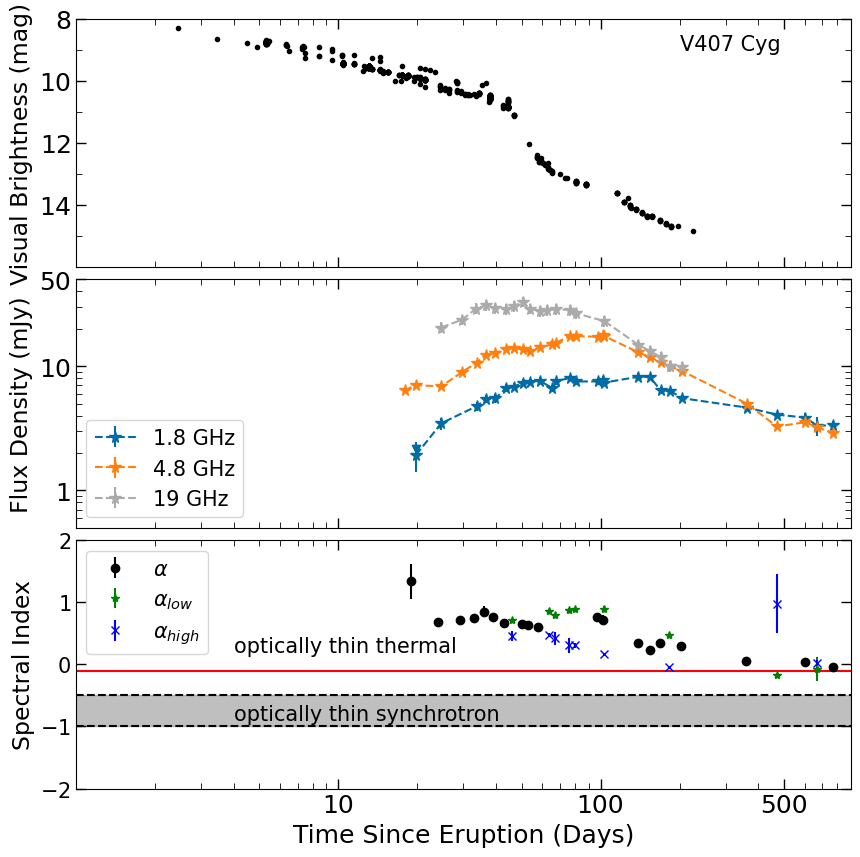

In [38]:
#plt.style.use('dark_background')
plt.style.use('tableau-colorblind10')

from matplotlib.ticker import AutoMinorLocator

fig, axs = plt.subplots(3, 1, figsize=(10, 10), sharey=False, sharex = True)#, constrained_layout=True)


#first the visual
axs[0].scatter(opticaldays, vmag, marker = '.', color = 'black')
axs[0].annotate('V407 Cyg',(200,9), fontsize=15)

axs[0].set_xscale('log')
#axs[0].set_yscale('log')

axs[0].set_ylabel('Visual Brightness (mag)',fontsize =17)

axs[0].set_yticks([8,10,12,14], labels = [r'$8$',r'$10$', r'$12$', r'$14$'], fontsize = 18)
axs[0].set_ylim(8,16)
axs[0].invert_yaxis()
axs[0].tick_params(which='minor', length=4, direction = 'in', top=True, labeltop=False, left=True, labelleft=False, bottom=True, labelbottom=False, right = True,labelright = False)
axs[0].yaxis.set_minor_locator(AutoMinorLocator(2))  # 2 minor intervals between major ticks
axs[0].tick_params(which='major', length=7, direction = 'in', width =1, top=True, labeltop=False, bottom=True, labelbottom=False, right = True, labelright = False)


#now the radio
axs[1].set_ylabel('Flux Density (mJy)',fontsize=17)
axs[1].set_xscale('log')
axs[1].set_yscale('log')


axs[1].errorbar(date_LBD, flux_LBD, yerr=quad_Lbd, linestyle ='--', fmt = '*' , markersize = 8.5, label='1.8 GHz')
axs[1].errorbar(date_CAC, flux_CAC, yerr=quad_Cac, linestyle ='--', fmt = '*', markersize = 8.5, label='4.8 GHz')
#axs[1].errorbar(date_CBD, flux_CBD, yerr=quad_Cbd, linestyle ='--', fmt = '*', markersize = 8.5 , label='7.4 Ghz')
axs[1].errorbar(date_K_BD, flux_K_BD, yerr=quad_Kbd, linestyle ='--', fmt = '*', markersize = 8.5 , label='19 GHz')
#axs[1].errorbar(date_Ka_BD, flux_Ka_BD, yerr=quad_Kabd, linestyle ='--', fmt = '*' , markersize = 8.5, label='36.5 GHz')


axs[1].scatter(ndate_LBD, nflux_LBD, marker = 'v')
axs[1].scatter(ndate_CAC, nflux_CAC, marker = 'v')
axs[1].scatter(ndate_K_BD, nflux_K_BD , marker = 'v')


axs[1].legend(fontsize=15, loc='lower left')
axs[1].set_yticks([1,10,50], labels = [r'$1$',r'$10$','50'], fontsize = 18)
axs[1].set_ylim([0.5,50])

axs[1].tick_params(which='minor', length =4, direction = 'in', top=True, labeltop=False, bottom=True, labelbottom=False, right = True,labelright = False)
axs[1].tick_params(which='major', length=7, direction = 'in', width =1, top=True, labeltop=False, bottom=True, labelbottom=False, right = True, labelright = False)

#axs[1].set_xticks([10,100,500], labels = ['10','100','500'], fontsize = 18)
#axs[1].set_xlim(1,900)

########### Panel 3 ############

axs[2].errorbar(alpha_day, alpha, yerr=alpha_err, marker = 'o',  linestyle = '', color = 'black', label=r'$\alpha$')
axs[2].errorbar(a12_day, a1, yerr=a1_err, marker = '*', linestyle = '', color = 'green', label=r'$\alpha_{low}$')
axs[2].errorbar(a12_day, a2, yerr=a2_err, marker = 'x', linestyle = '',color = 'blue', label=r'$\alpha_{high}$')

axs[2].axhline(y = -0.1, color = 'red', linestyle = '-')
axs[2].axhline(y = -0.5, color = 'black', linestyle = '--')
axs[2].axhline(y = -1, color = 'black', linestyle = '--')
axs[2].fill_between(x=[0.1,900],y1=-0.5,y2=-1, color = 'grey', alpha=.5)

axs[2].set_xlabel('Time Since Eruption (Days)', fontsize=18)
axs[2].set_ylabel('Spectral Index', fontsize=17)
axs[2].annotate('optically thin thermal', (4,0.2), fontsize=15)
axs[2].annotate('optically thin synchrotron', (4,-0.9), fontsize=15)

axs[2].set_xticks([10,100,500], labels = ['10','100','500'], fontsize = 18)

axs[2].set_yticks([-2,-1,0,1,2], labels = [r'$-2$',r'$-1$',r'$0$',r'$1$',r'$2$'], fontsize = 15)
axs[2].set_ylim(-2,2)
axs[2].set_xlim(1,900)

axs[2].tick_params(which='minor', length =4, direction = 'in', top=True, labeltop=False, bottom=True, labelbottom=False, right = True,labelright = False)
axs[2].tick_params(which='major', length=7, direction = 'in', width =1, top=True, labeltop=False, bottom=True, labelbottom=True, right = True, labelright = False)

axs[2].legend(fontsize=15, loc='upper left')




fig.subplots_adjust(hspace=0.05)
plt.savefig("V407Cyg_RadioOptical_lightcurves.png")
plt.show();
